In [26]:
# Compare GPR models using a smaller minimum length-scale bound.
# Evaluate and tune Gaussian Process hyperparameters
# 1 GPR model for each of the 3 target properties 
# Compare kernel settings using leave-one-out cross-validation (R²)
# Visualize 1D slices of the full GP by varying one ingredient while holding
# others constant, sampling 5 posterior functions

In [27]:
# import data

from pathlib import Path
import pandas as pd

# Load the compiled data
project_root = Path.cwd().resolve().parent if 'notebooks' in str(Path.cwd()) else Path.cwd().resolve()
excel_path = project_root / 'data' / 'raw' / 'Compiled Data.xlsx'

df = pd.read_excel(excel_path)

print()

In [28]:
# Show the 25 original formulas and their three measured targets from df.
formula_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
measured_target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
raw_data_summary = df[formula_cols + measured_target_cols].copy()
raw_data_summary[formula_cols] = raw_data_summary[formula_cols].fillna(0.0)
raw_data_summary[measured_target_cols] = raw_data_summary[measured_target_cols].apply(
    pd.to_numeric, errors="raise"
)

assert len(raw_data_summary) == 25, (
    f"Expected the 25 original samples; found {len(raw_data_summary)}."
)
display(raw_data_summary)

,TEM,Joncryl,NC513,PEG-DE,NGDE,Avg_Density_g_cm3,24h_avg_pct absorption,24h_avg_pct_retention
0,8,0.0,0.0,0.0,0.0,0.192000,113.616943,31.770000
1,8,0.7,0.0,0.0,0.0,0.195000,103.817309,33.120000
2,8,1.0,0.0,0.0,0.0,0.159000,129.464292,36.250000
3,8,1.5,0.0,0.0,0.0,0.159933,120.749405,25.330000
4,8,2.0,0.0,0.0,0.0,0.201000,113.871581,26.580000
5,8,3.0,0.0,0.0,0.0,0.202000,111.044347,27.400000
6,5,0.0,0.0,0.0,0.0,0.298930,56.958538,36.614852
7,5,0.0,0.7,0.0,0.0,0.360035,57.115160,44.587460
8,5,0.0,1.0,0.0,0.0,0.355557,44.308895,43.766577
9,5,0.0,2.0,0.0,0.0,0.358055,43.326301,44.186536


In [29]:
# Train one Gaussian process regressor per target, using LOOCV on all 25 samples.

# gpr_models stores our 3 models trained on all 25 samples

import numpy as np
from sklearn.base import clone
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

feature_cols = ["TEM", "Joncryl", "NC513", "PEG-DE", "NGDE"]
target_cols = [
    "Avg_Density_g_cm3",
    "24h_avg_pct absorption",
    "24h_avg_pct_retention",
]
target_labels = {
    "Avg_Density_g_cm3": "Average density (g/cm^3)",
    "24h_avg_pct absorption": "24-hour absorption (%)",
    "24h_avg_pct_retention": "24-hour retention (%)",
}

# Blank ingredient cells mean that ingredient was not used in the formula.
model_data = df[feature_cols + target_cols].copy()
model_data[feature_cols] = model_data[feature_cols].fillna(0.0)
model_data[target_cols] = model_data[target_cols].apply(pd.to_numeric, errors="raise")

assert len(model_data) == 25, f"Expected all 25 samples; found {len(model_data)}."
assert not model_data[target_cols].isna().any().any(), "A target contains missing values."

X = model_data[feature_cols]
loo = LeaveOneOut()
gpr_models = {}
cv_predictions = pd.DataFrame(index=model_data.index)
results = []

for target in target_cols:
    y = model_data[target]
    kernel = (
        ConstantKernel(1.0, (1e-3, 1e3))
        * Matern(
            length_scale=np.ones(len(feature_cols)),
            length_scale_bounds=(1e-2, 1e3),
            nu=2.5,
        )
        + WhiteKernel(noise_level=1e-3, noise_level_bounds=(1e-8, 1e1))
    )
    estimator = make_pipeline(
        StandardScaler(),
        GaussianProcessRegressor(
            kernel=kernel,
            normalize_y=True,
            n_restarts_optimizer=5,
            random_state=42,
        ),
    )

    # cross_val_predict clones and refits the estimator for every held-out sample.
    oof_prediction = cross_val_predict(clone(estimator), X, y, cv=loo, n_jobs=1)
    cv_predictions[f"{target} - LOOCV prediction"] = oof_prediction

    # Fit the final deployable model on all 25 observations; GPR optimizes kernel
    # hyperparameters by maximizing the log marginal likelihood during fit.
    final_model = clone(estimator).fit(X, y)
    gpr_models[target] = final_model

    results.append(
        {
            "target": target,
            "LOOCV R2": r2_score(y, oof_prediction),
            "LOOCV MAE": mean_absolute_error(y, oof_prediction),
            "LOOCV RMSE": np.sqrt(mean_squared_error(y, oof_prediction)),
            "optimized kernel (all 25 samples)": str(
                final_model.named_steps["gaussianprocessregressor"].kernel_
            ),
        }
    )

results_df = pd.DataFrame(results).set_index("target")
print("LOOCV performance:")
display(results_df)
print("\nFirst five out-of-fold predictions:")
display(cv_predictions.head())

c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:455: ConvergenceWarning: The optimal value found for dimension 3 of parameter k1__k2__length_scale is close to the specified upper bound 1000.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\Brooke\Foam project\.venv\Lib\site

LOOCV performance:


,LOOCV R2,LOOCV MAE,LOOCV RMSE,optimized kernel (all 25 samples)
target,,,,
Avg_Density_g_cm3,0.865830,0.018787,0.023439,"0.973**2 * Matern(length_scale=[0.232, 1.22, 1..."
24h_avg_pct absorption,0.859557,22.804300,29.089821,"0.907**2 * Matern(length_scale=[3.26, 2.2, 4.5..."
24h_avg_pct_retention,0.734585,5.016150,6.683203,"1.06**2 * Matern(length_scale=[8.06, 0.563, 1...."



First five out-of-fold predictions:


,Avg_Density_g_cm3 - LOOCV prediction,24h_avg_pct absorption - LOOCV prediction,24h_avg_pct_retention - LOOCV prediction
0,0.204338,140.073728,29.026324
1,0.164137,126.649184,31.170363
2,0.165689,110.308253,38.659445
3,0.163207,134.446643,32.554296
4,0.165964,110.056105,28.515628


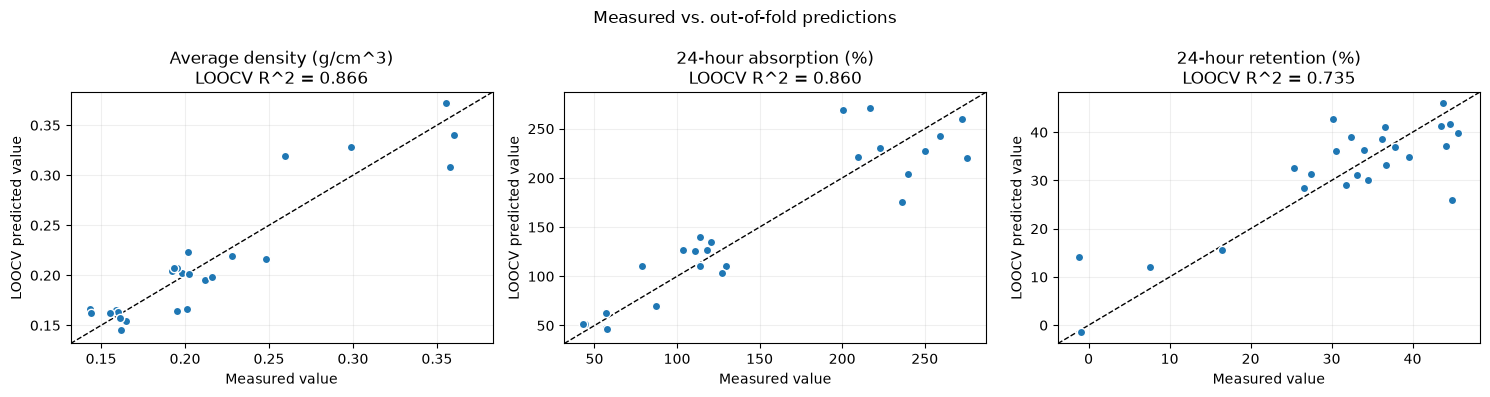

Fixed ingredient values:


,Fixed value
TEM,8.0
NC513,0.0
PEG-DE,0.0
NGDE,0.0


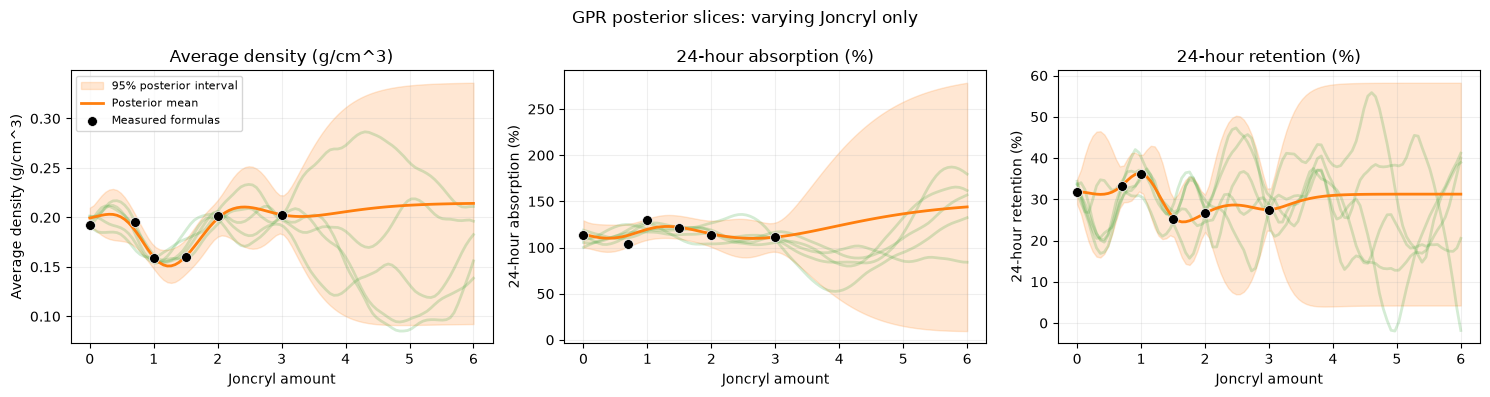

In [30]:
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score

# Compare held-out LOOCV predictions with the measured values.
fig, axes = plt.subplots(1, len(target_cols), figsize=(15, 4), squeeze=False)
for col, target in enumerate(target_cols):
    axis = axes[0, col]
    actual = model_data[target].to_numpy()
    predicted = cv_predictions[f"{target} - LOOCV prediction"].to_numpy()
    lower = min(actual.min(), predicted.min())
    upper = max(actual.max(), predicted.max())
    padding = (upper - lower) * 0.05 or 1.0
    limits = (lower - padding, upper + padding)
    axis.scatter(actual, predicted, color="tab:blue", edgecolor="white", zorder=3)
    axis.plot(limits, limits, linestyle="--", color="black", linewidth=1)
    axis.set_xlim(limits)
    axis.set_ylim(limits)
    axis.set_title(f"{target_labels[target]}\nLOOCV R^2 = {r2_score(actual, predicted):.3f}")
    axis.set_xlabel("Measured value")
    axis.set_ylabel("LOOCV predicted value")
    axis.grid(alpha=0.2)
fig.suptitle("Measured vs. out-of-fold predictions")
fig.tight_layout()
plt.show()


# Select formulas where Joncryl is the only ingredient that varies.
fixed_cols = [col for col in feature_cols if col != "Joncryl"]
fixed_values = X.iloc[0][fixed_cols]
same_formula = np.isclose(X[fixed_cols], fixed_values).all(axis=1)
joncryl_data = X.loc[same_formula]

if len(joncryl_data) != 6:
    raise ValueError(
        f"Expected 6 formulas with only Joncryl varying; found {len(joncryl_data)}."
    )

baseline_formula = joncryl_data.iloc[0].copy()
print("Fixed ingredient values:")
display(fixed_values.to_frame("Fixed value"))

n_grid = 100
n_posterior_samples = 5
rng = np.random.default_rng(42)
joncryl_grid = np.linspace(0.0, 6.0, n_grid)

grid_data = pd.DataFrame(
    np.repeat(baseline_formula.to_numpy()[None, :], n_grid, axis=0),
    columns=feature_cols,
)
grid_data["Joncryl"] = joncryl_grid

fig, axes = plt.subplots(1, len(target_cols), figsize=(15, 4), squeeze=False)

for col, target in enumerate(target_cols):
    axis = axes[0, col]
    pipeline = gpr_models[target]
    scaled_grid = pipeline.named_steps["standardscaler"].transform(grid_data)
    gpr = pipeline.named_steps["gaussianprocessregressor"]
    mean, covariance = gpr.predict(scaled_grid, return_cov=True)

    target_scale = model_data[target].std(ddof=0)
    if target_scale == 0:
        target_scale = 1.0
    observation_noise = gpr.kernel_.k2.noise_level * target_scale**2
    covariance -= observation_noise * np.eye(n_grid)
    covariance = (covariance + covariance.T) / 2

    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    covariance_factor = eigenvectors * np.sqrt(np.clip(eigenvalues, 0, None))
    posterior_samples = (
        mean[:, None]
        + covariance_factor @ rng.standard_normal((n_grid, n_posterior_samples))
    )

    for sample_index in range(n_posterior_samples):
        axis.plot(
            joncryl_grid,
            posterior_samples[:, sample_index],
            color="tab:green",
            alpha=0.20,
            linewidth=2,
        )

    posterior_std = np.sqrt(np.clip(np.diag(covariance), 0, None))
    axis.fill_between(
        joncryl_grid,
        mean - 1.96 * posterior_std,
        mean + 1.96 * posterior_std,
        color="tab:orange",
        alpha=0.18,
        label="95% posterior interval",
    )
    axis.plot(
        joncryl_grid, mean, color="tab:orange", linewidth=2, label="Posterior mean"
    )
    axis.scatter(
        joncryl_data["Joncryl"],
        model_data.loc[joncryl_data.index, target],
        color="black",
        edgecolor="white",
        linewidth=0.5,
        s=50,
        zorder=5,
        label="Measured formulas",
    )

    axis.set_title(target_labels[target])
    axis.set_xlabel("Joncryl amount")
    axis.set_ylabel(target_labels[target])
    axis.grid(alpha=0.2)
    if col == 0:
        axis.legend(loc="best", fontsize=8)

fig.suptitle("GPR posterior slices: varying Joncryl only")
fig.tight_layout()
plt.show()